<a href="https://colab.research.google.com/github/Devaji-Rashmika/Deep_Learning/blob/main/Skill3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install ultralytics fastapi uvicorn python-multipart httpx pillow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 21.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


In [2]:
import torch

print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    device = "0"
    print("GPU:", torch.cuda.get_device_name(0))
else:
    device = "cpu"
    print("Using CPU")

PyTorch Version: 2.14.1+cpu
CUDA Available: False
Using CPU


In [3]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

print("VisionPort YOLO model loaded!")
print("Model:", "YOLO11n")
print("Device:", device)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
VisionPort YOLO model loaded!
Model: YOLO11n
Device: cpu


In [4]:
from fastapi import FastAPI, UploadFile, File, HTTPException
from PIL import Image
from io import BytesIO
from collections import Counter
import time

app = FastAPI(title="VisionPort - Inference Request Trace")

@app.get("/")
def home():
    return {
        "project": "VisionPort",
        "status": "Running",
        "model": "YOLO11n"
    }

In [5]:
@app.post("/infer")
async def inference(file: UploadFile = File(...)):

    # STAGE 1: API INPUT
    if not file.content_type or not file.content_type.startswith("image/"):
        raise HTTPException(
            status_code=400,
            detail="Please upload a valid image"
        )

    try:
        api_start = time.perf_counter()

        image_bytes = await file.read()

        # STAGE 2: IMAGE PREPROCESSING
        preprocessing_start = time.perf_counter()

        image = Image.open(
            BytesIO(image_bytes)
        ).convert("RGB")

        original_width, original_height = image.size

        preprocessing_time = (
            time.perf_counter() - preprocessing_start
        ) * 1000

        # STAGE 3 AND 4: MODEL EXECUTION
        inference_start = time.perf_counter()

        results = model.predict(
            source=image,
            imgsz=640,
            conf=0.25,
            device=device,
            verbose=False
        )

        inference_time = (
            time.perf_counter() - inference_start
        ) * 1000

        result = results[0]

        # STAGE 5: POSTPROCESSING
        postprocessing_start = time.perf_counter()

        detections = []

        for box in result.boxes:

            class_id = int(box.cls[0])

            object_name = result.names[class_id]

            confidence = float(box.conf[0])

            coordinates = [
                round(float(value), 2)
                for value in box.xyxy[0].tolist()
            ]

            detections.append({
                "object": object_name,
                "confidence": round(confidence * 100, 2),
                "bounding_box": coordinates
            })

        object_counts = dict(
            Counter(
                item["object"] for item in detections
            )
        )

        postprocessing_time = (
            time.perf_counter() - postprocessing_start
        ) * 1000

        total_time = (
            time.perf_counter() - api_start
        ) * 1000

        # STAGE 6: API RESPONSE
        return {
            "status": "success",
            "filename": file.filename,

            "image_details": {
                "width": original_width,
                "height": original_height
            },

            "total_objects": len(detections),

            "object_counts": object_counts,

            "detections": detections,

            "inference_trace": {
                "preprocessing_ms": round(preprocessing_time, 2),
                "model_execution_ms": round(inference_time, 2),
                "postprocessing_ms": round(postprocessing_time, 2),
                "total_request_ms": round(total_time, 2)
            }
        }

    except HTTPException:
        raise

    except Exception as e:
        raise HTTPException(
            status_code=400,
            detail=str(e)
        )

In [6]:
from fastapi.testclient import TestClient

client = TestClient(app)

response = client.get("/")

print("Status Code:", response.status_code)
print("Response:", response.json())

Status Code: 200
Response: {'project': 'VisionPort', 'status': 'Running', 'model': 'YOLO11n'}


In [7]:
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded.keys()))

print("Uploaded Image:", filename)

Saving Screenshot 2026-11-11 101343.png to Screenshot 2026-11-11 101343.png
Uploaded Image: Screenshot 2026-11-11 101343.png


In [8]:
with open(filename, "rb") as image_file:

    response = client.post(
        "/infer",
        files={
            "file": (
                filename,
                image_file,
                "image/jpeg"
            )
        }
    )

print("HTTP Status:", response.status_code)

data = response.json()

print("\nVISIONPORT API RESPONSE")
print("========================")

print("Status:", data["status"])
print("Filename:", data["filename"])

print("Image Dimensions:", data["image_details"])

print("Total Objects:", data["total_objects"])

print("\nObject Counts:")

for name, count in data["object_counts"].items():
    print(name, ":", count)

print("\nIndividual Detections:")

for detection in data["detections"]:
    print(detection)

HTTP Status: 200

VISIONPORT API RESPONSE
Status: success
Filename: Screenshot 2026-11-11 101343.png
Image Dimensions: {'width': 787, 'height': 512}
Total Objects: 19

Object Counts:
car : 15
truck : 1
person : 2
bus : 1

Individual Detections:
{'object': 'car', 'confidence': 90.54, 'bounding_box': [105.16, 340.9, 282.92, 471.79]}
{'object': 'car', 'confidence': 86.82, 'bounding_box': [318.78, 335.01, 482.2, 471.8]}
{'object': 'car', 'confidence': 82.79, 'bounding_box': [222.93, 253.49, 342.4, 355.7]}
{'object': 'car', 'confidence': 81.83, 'bounding_box': [551.97, 218.15, 643.42, 311.64]}
{'object': 'car', 'confidence': 76.97, 'bounding_box': [376.48, 210.8, 493.88, 317.35]}
{'object': 'car', 'confidence': 74.37, 'bounding_box': [445.47, 185.32, 529.11, 267.35]}
{'object': 'car', 'confidence': 73.67, 'bounding_box': [258.85, 140.97, 370.01, 206.7]}
{'object': 'car', 'confidence': 68.0, 'bounding_box': [349.93, 162.16, 438.85, 236.53]}
{'object': 'truck', 'confidence': 62.69, 'bounding_

In [9]:
trace = data["inference_trace"]

print("\n========== INFERENCE REQUEST TRACE ==========")

print("Image Preprocessing:", trace["preprocessing_ms"], "ms")

print("Model Execution:", trace["model_execution_ms"], "ms")

print("Postprocessing:", trace["postprocessing_ms"], "ms")

print("Total Request Time:", trace["total_request_ms"], "ms")

print("==============================================")


========== INFERENCE REQUEST TRACE ==========
Image Preprocessing: 67.43 ms
Model Execution: 10598.54 ms
Postprocessing: 13.21 ms
Total Request Time: 10679.36 ms


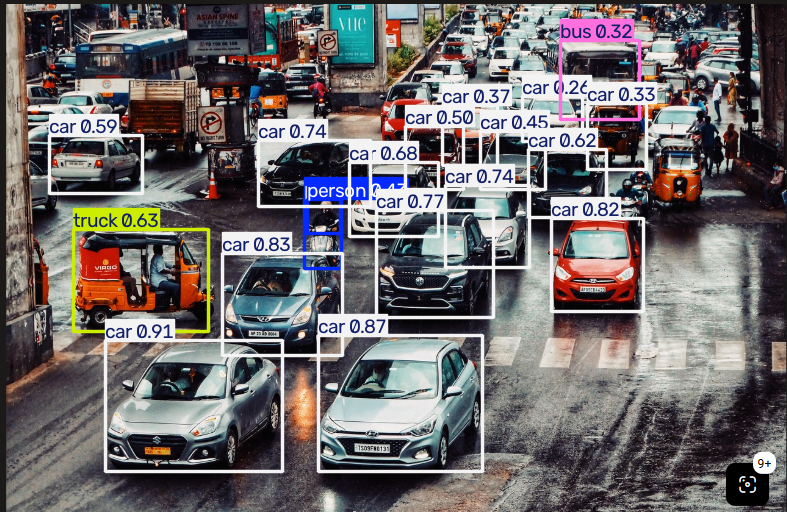

In [10]:
from IPython.display import display

# Run detection for visualization
results = model.predict(
    source=filename,
    imgsz=640,
    conf=0.25,
    device=device,
    verbose=False
)

# Generate annotated image
annotated_image = results[0].plot()

# Display the result
display(
    Image.fromarray(annotated_image[:, :, ::-1])
)